In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

In [2]:
GAUSS_X = np.linspace(-3, 3, 1000)
GAUSS_Y = norm.cdf(GAUSS_X)

In [3]:
def gen_gauss(n: int) -> tuple[np.NDArray[np.float64], np.NDArray[np.float64]]:
    g = np.random.normal(size=n*2) # N(0, 1)

    # Сортируем и получаем вариационный ряд
    gvs = np.sort(g[:len(g)//2])

    # Получаем эмпирическую функцию распределения
    return g[:len(g)//2], gvs, np.arange(1, gvs.size + 1) / gvs.size

def display_gauss(n: int, bins=4):
    g, gvs, cdf = gen_gauss(n)
    
    plt.plot(GAUSS_X, GAUSS_Y, label="Теоретическая ф.р.")
    plt.step(gvs, cdf, where='post', label="Эмпирическая ф.р.")
    plt.legend()
    plt.title(f"N = {n}")
    plt.grid(True)
    plt.show()

    plt.hist(gvs, bins=30, density=True, alpha=0.5)
    plt.show()

    plt.scatter(gvs, g, color='red', s=10)

    plt.show()

    x_edges = np.linspace(gvs.min(), gvs.max(), bins + 1)
    y_edges = np.linspace(g.min(), g.max(), bins + 1)

    counts, x_edges, y_edges = np.histogram2d(gvs, g, bins=[x_edges, y_edges])

    X, Y = np.meshgrid(x_edges[:-1], y_edges[:-1], indexing='ij')

    dx = x_edges[1] - x_edges[0]
    dy = y_edges[1] - y_edges[0]

    fig = plt.figure(figsize=(10, 8))
    ax = fig.add_subplot(111, projection='3d')

    ax.bar3d(
        X.ravel(), Y.ravel(),
        np.zeros_like(counts).ravel(),
        dx, dy,
        counts.ravel(),
        shade=True,
        color='cyan',
        edgecolor='black',
        linewidth=0.5,
    )

    ax.set_xticks(x_edges)
    ax.set_yticks(y_edges)

    plt.tight_layout()
    plt.show()

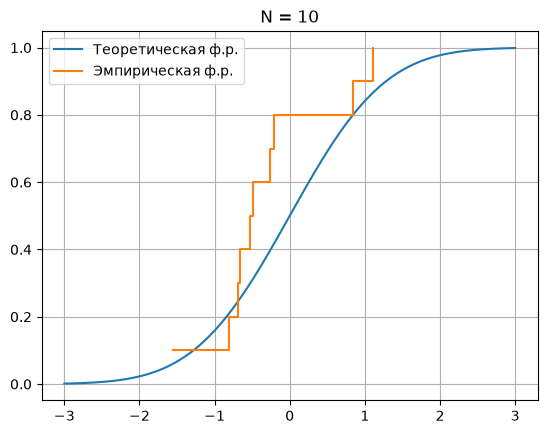

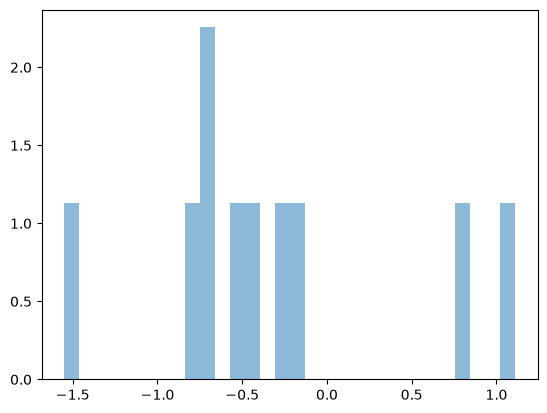

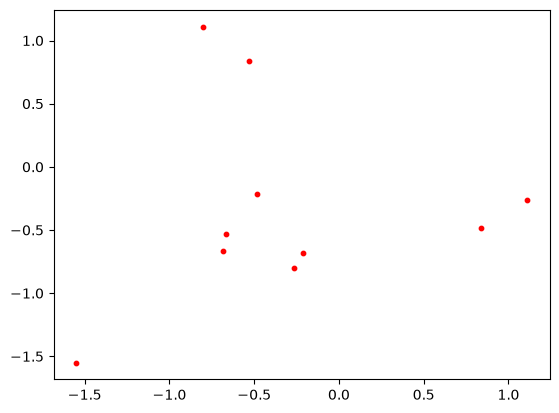

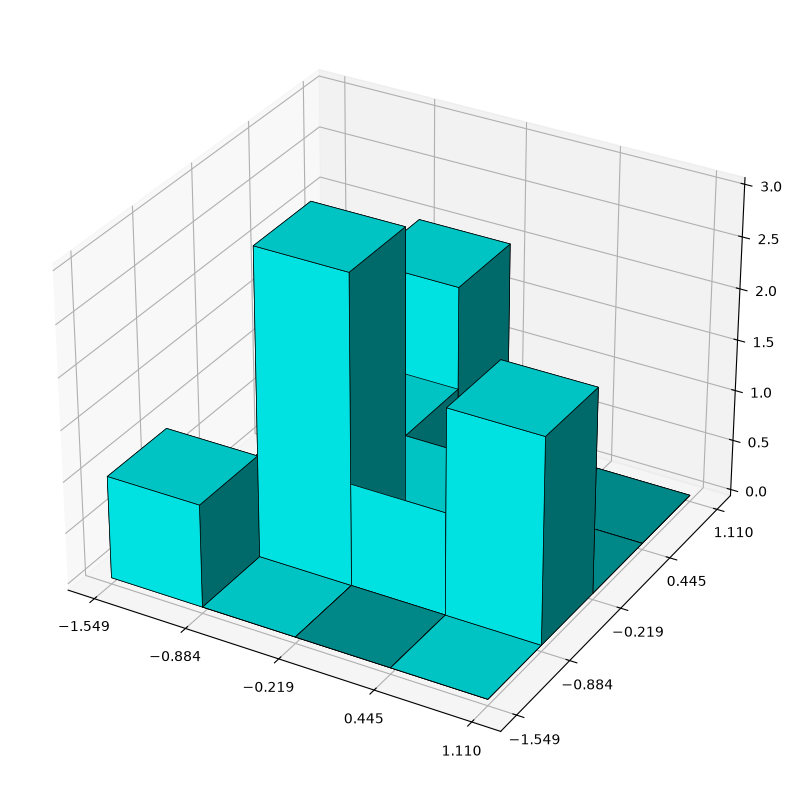

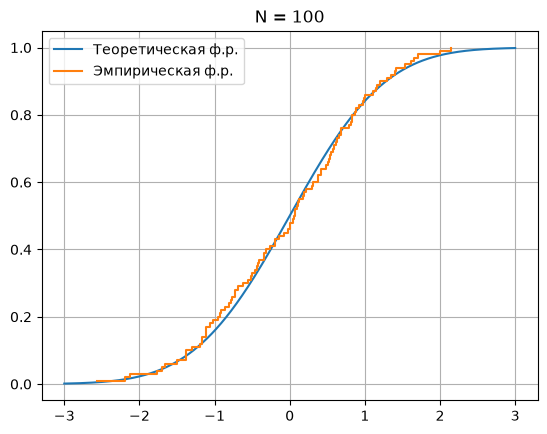

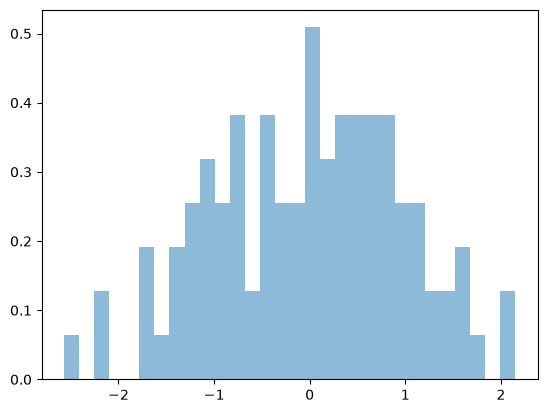

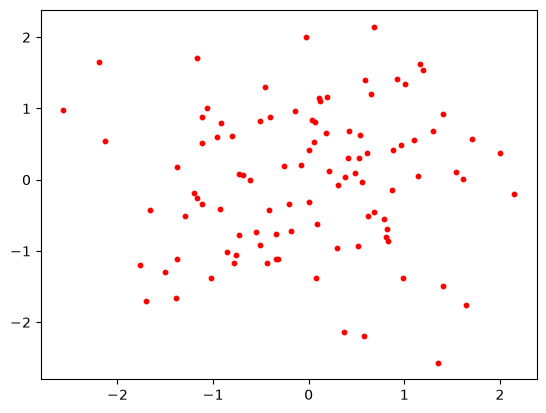

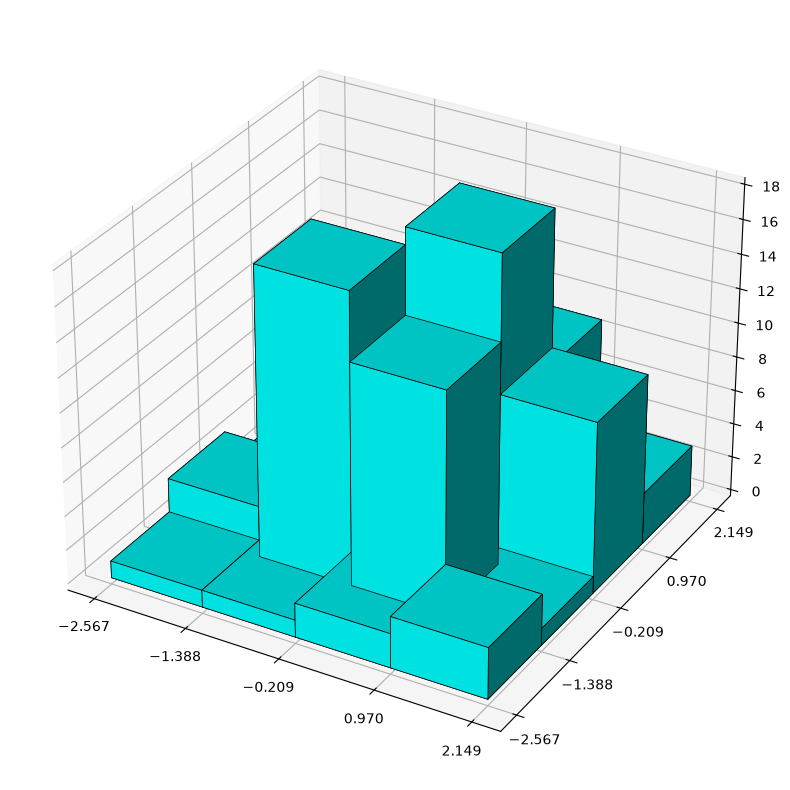

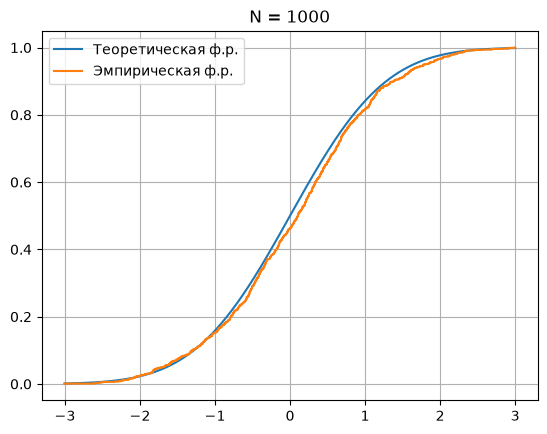

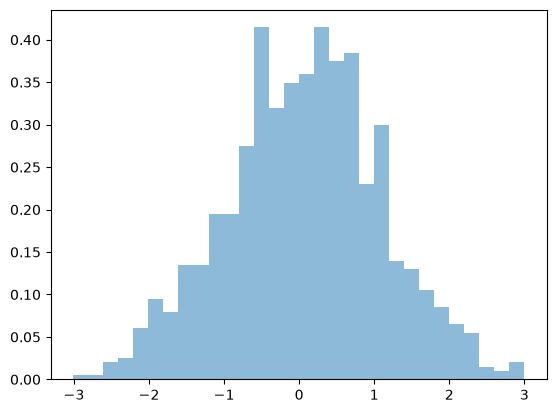

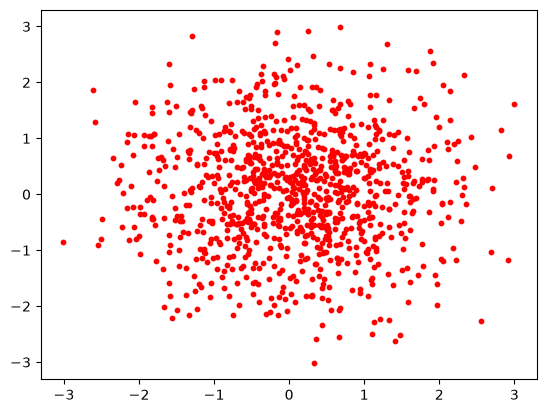

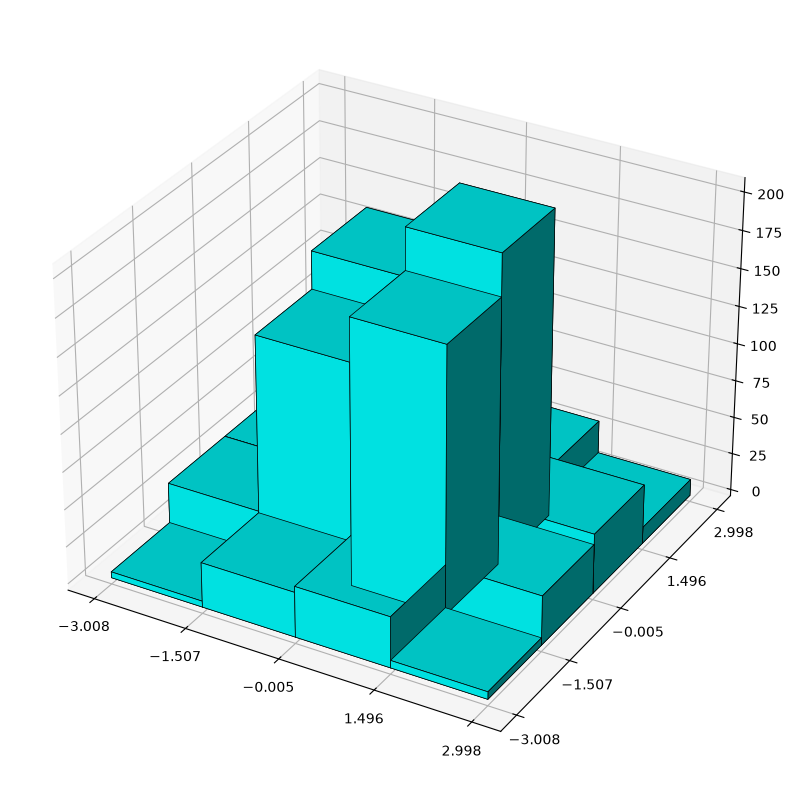

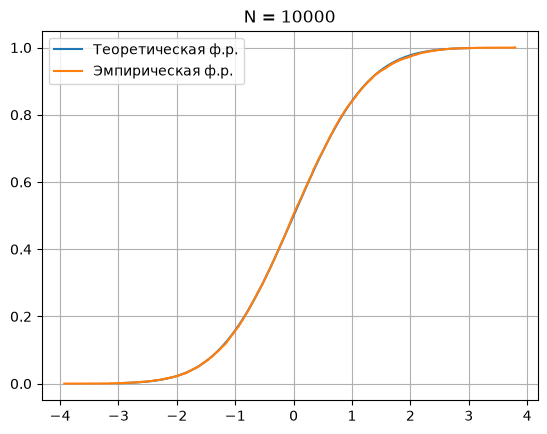

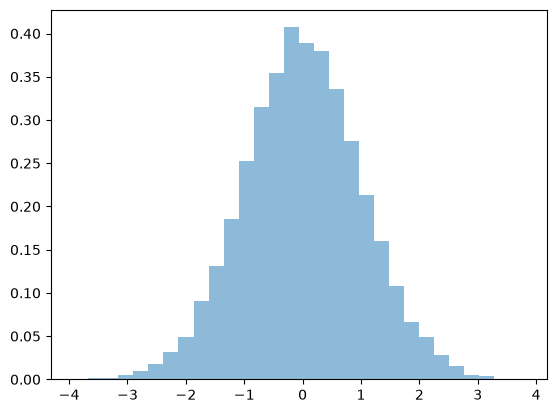

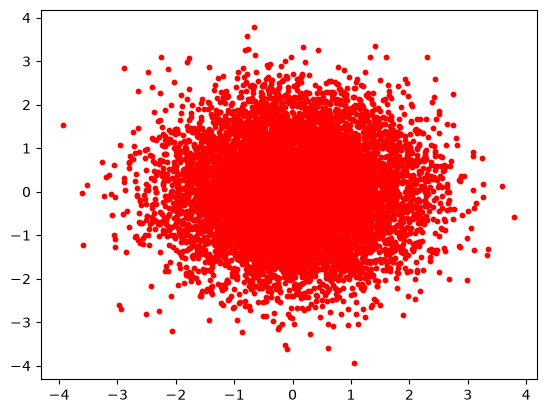

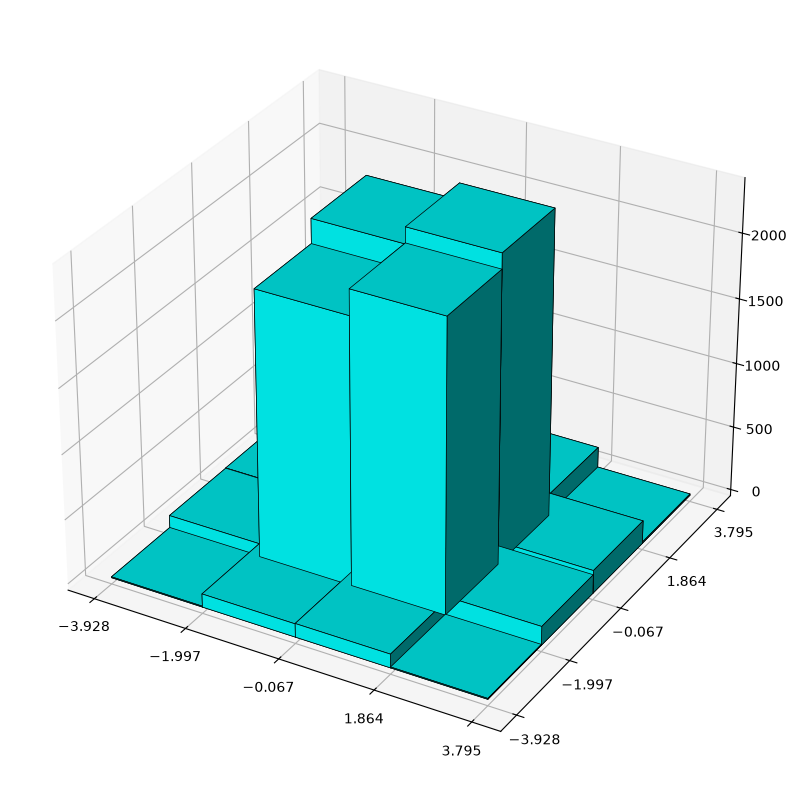

In [4]:
display_gauss(10)
display_gauss(100)
display_gauss(1000)
display_gauss(10000)

Лаба 2

In [5]:
from scipy.special import erfinv

In [6]:
def quantile(p: float):
    return np.sqrt(2) * erfinv(2 * p - 1)

In [7]:
def calc_chars(n: int):
    g = np.random.normal(size=n*2)
    x, y = g[:len(g)//2], g[len(g)//2:]

    x_mean = x.mean()
    y_mean = y.mean()

    x_var = ((x - x_mean) ** 2).sum() / n
    y_var = ((y - y_mean) ** 2).sum() / n

    x_var_unb = x_var * n / (n - 1)
    y_var_unb = y_var * n / (n - 1)

    x_std = np.sqrt(x_var_unb)
    y_std = np.sqrt(y_var_unb)

    cov = ((x - x_mean) * (y - y_mean)).sum() / (n - 1)
    corr = cov / (x_std * y_std)

    x_q1, x_med, x_q3 = np.quantile(x, [0.25, 0.5, 0.75])
    y_q1, y_med, y_q3 = np.quantile(y, [0.25, 0.5, 0.75])

    print(f"N = {n}")
    print(f"Среднее: {x_mean}, {y_mean}")
    print(f"Дисперсия (смещённая): {x_var}, {y_var}")
    print(f"Дисперсия (несмещённая): {x_var_unb}, {y_var_unb}")
    print(f"Стандартное отклонение: {x_std}, {y_std}")
    print(f"Медиана: {x_med}, {y_med}")
    print(f"Нижний квартиль: {x_q1}, {y_q1}")
    print(f"Верхний квартиль: {x_q3}, {y_q3}")
    print(f"Ковариация: {cov}")
    print(f"Корреляция: {corr}\n")

    q1, q2, q3 = quantile(0.25), quantile(0.5), quantile(0.75)

    print(f"Погрешность среднего: {abs(x_mean)}, {abs(y_mean)}")
    print(f"Погрешность дисперсии (смещённая): {abs(x_var - 1)}, {abs(y_var - 1)}")
    print(f"Погрешность дисперсии (несмещённая): {abs(x_var_unb - 1)}, {abs(y_var_unb - 1)}")
    print(f"Погрешность стандартного отклонения: {abs(x_std - 1)}, {abs(y_std - 1)}")
    print(f"Погрешность медианы: {abs(x_med - q2)}, {abs(y_med - q2)}")
    print(f"Погрешность нижнего квартиля: {abs(x_q1 - q1)}, {abs(y_q1 - q1)}")
    print(f"Погрешность верхнего квартиля: {abs(x_q3 - q3)}, {abs(y_q3 - q3)}")
    print(f"Погрешность ковариации: {abs(cov)}")
    print(f"Погрешность корреляции: {abs(corr)}")

    return x

N = 10
Среднее: 0.017917757549414604, -0.22432574701045455
Дисперсия (смещённая): 0.18345986422554383, 0.7242812437323691
Дисперсия (несмещённая): 0.2038442935839376, 0.8047569374804101
Стандартное отклонение: 0.4514911888220385, 0.8970824585735752
Медиана: 0.1302441986832632, -0.05698662157131824
Нижний квартиль: -0.30197885145827685, -0.9337175362555834
Верхний квартиль: 0.2634105709684024, 0.2574065908790126
Ковариация: 0.1499706790651999
Корреляция: 0.37027527586409154

Погрешность среднего: 0.017917757549414604, 0.22432574701045455
Погрешность дисперсии (смещённая): 0.8165401357744562, 0.27571875626763087
Погрешность дисперсии (несмещённая): 0.7961557064160624, 0.1952430625195899
Погрешность стандартного отклонения: 0.5485088111779615, 0.10291754142642484
Погрешность медианы: 0.1302441986832632, 0.05698662157131824
Погрешность нижнего квартиля: 0.37251089873780496, 0.2592277860595016
Погрешность верхнего квартиля: 0.4110791792276794, 0.41708315931706924
Погрешность ковариации: 0.1

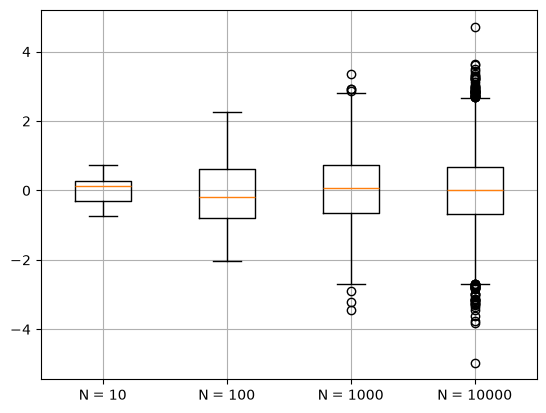

In [8]:
x1 = calc_chars(10)
x2 = calc_chars(100)
x3 = calc_chars(1000)
x4 = calc_chars(10000)

plt.boxplot([x1, x2, x3, x4], tick_labels=["N = 10", "N = 100", "N = 1000", "N = 10000"])
plt.grid(True)
plt.show()

In [9]:
def print_uniform_params(n: int, a = 0, b = 1):
    u = np.random.uniform(a, b, n)

    a_hat, b_hat = u.min(), u.max()
    print(f"n={n}, a={a}, b={b}, погрешность a: {abs(a - a_hat)}, погрешность b: {abs(b - b_hat)}")

In [10]:
print_uniform_params(10)
print_uniform_params(100)
print_uniform_params(1000)
print_uniform_params(10000)

n=10, a=0, b=1, погрешность a: 0.16097053336617628, погрешность b: 0.08571020330196943
n=100, a=0, b=1, погрешность a: 0.0013263631842154178, погрешность b: 0.011667468669794734
n=1000, a=0, b=1, погрешность a: 0.0011991863234995792, погрешность b: 0.0008327450077392218
n=10000, a=0, b=1, погрешность a: 2.8717533617550473e-05, погрешность b: 3.219122624109616e-05
